# Task 4 — Tableau Storytelling and Critical Reflection

| | |
|---|---|
| **Module** | 7006SCN Machine Learning and Big Data |
| **Student** | Manish Saini — SID 17142113 — sainim10@coventry.ac.uk |
| **Pool reference** | 112 |
| **Dataset** | NOAA GHCN-Daily, US stations (`CatLikeIceCream/temperature`, `climate.csv`) |
| **Problem** | Regression: predict `label_TMAX_next`, the next-day maximum temperature (°C) at the same station |
 

## 0 Setup
### 0.1 Environment, paths and run settings
These are the same Windows settings as Tasks 1–3. The repository root must hold `results/task1.json` (with the handoff block), `results/task2.json` and `results/task3.json`.

In [1]:
# ==============================================================================
# 0.1  Environment, paths and run settings
# REF: Task 3 notebook, cell 0.1 - the same Windows/Hadoop settings and repository-root search
## AI: settings block and output-folder layout written with AI assistance
# ==============================================================================
import os, sys, json, time, math, platform, tempfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore", category=UserWarning)

if os.name == "nt":
    os.environ["HADOOP_HOME"] = os.environ.get("HADOOP_HOME", r"E:\hadoop")
    os.environ["PATH"] = os.environ["HADOOP_HOME"] + r"\bin;" + os.environ["PATH"]
    LOCAL_DIR = os.environ.get("CW_LOCAL_DIR", "E:/spark-tmp")
    os.environ["TEMP"] = os.environ["TMP"] = LOCAL_DIR
else:
    LOCAL_DIR = os.environ.get("CW_LOCAL_DIR", os.path.join(tempfile.gettempdir(), "spark-tmp"))
os.makedirs(LOCAL_DIR, exist_ok=True)


def find_project_root():
    """The nearest folder (this one or above) with results/task1.json (handoff), task2.json and task3.json."""
    tried = []
    for candidate in (Path("."), Path(".."), Path("../..")):
        f = candidate / "results" / "task1.json"
        if f.exists():
            tried.append(f.resolve().as_posix())
            h = json.loads(f.read_text()).get("handoff")
            if (h and (candidate / h["train_path"]).exists() and (candidate / "results" / "task2.json").exists()
                    and (candidate / "results" / "task3.json").exists()):
                return candidate
    raise FileNotFoundError(f"No repository root with results/task1.json, task2.json and task3.json was found "
                            f"(checked: {tried}). Run Tasks 1-3 first and open this notebook from notebooks/.")


ROOT = find_project_root()

# ---- run settings ----
QUICK_TEST           = False                      # True = small samples, outputs go to task4/quick_test/
SEED                 = 42
PLOT_PER_MILLE       = 12                         # the same ~1.2% of test days as Fig. 2.1, EP2 and Fig. 3.3
RUN_SCALING          = True                       # D4: time training on 10/25/50/100% of the training rows
SCALING_FRACTIONS    = [0.1, 0.25] if QUICK_TEST else [0.1, 0.25, 0.5, 1.0]
HOT_EVENT, COLD_EVENT = 35.0, -10.0               # deg C: the days a heat / cold warning is meant to catch
TABLEAU_PUBLIC_URL   = "https://public.tableau.com/app/profile/manish.saini8855/viz/7006SCNManishSaininext-dayTMAXforecasting/D1Dataqualitypipelinemonitoring"                         # published Tableau Public workbook
NOTEBOOK             = "notebooks/task4.ipynb"

OUT_DIR = ROOT / "task4" / ("quick_test" if QUICK_TEST else "")
TAB_DIR = OUT_DIR / "tableau"                     # the files Tableau connects to
RES_DIR = OUT_DIR / "results"
FIG_DIR = OUT_DIR / "figures"
DASH_DIR = OUT_DIR / "dashboards"                 # put the four dashboard images exported from Tableau here
for d in (TAB_DIR, RES_DIR, FIG_DIR, DASH_DIR):
    d.mkdir(parents=True, exist_ok=True)


def spark_path(p):
    return Path(p).resolve().as_posix()


def rel(p):
    return Path(os.path.relpath(Path(p).resolve(), ROOT.resolve())).as_posix()


def show(df, title=None):
    if title:
        print(title)
    try:
        from IPython.display import display
        display(df)
    except Exception:
        print(df.to_string(index=False))


EXPORTS = {}                                      # table name -> (dashboard, DataFrame)


def export(name, dashboard, df):
    """Keep a table for Tableau: one CSV now, and one Excel sheet when section 4.2 runs."""
    EXPORTS[name] = (dashboard, df)
    df.to_csv(TAB_DIR / f"{name}.csv", index=False)
    print(f"  {dashboard}  {name:<28} {len(df):>6,} rows x {df.shape[1]} columns")


print(f"repository root : {ROOT.resolve()}")
print(f"Tableau files   : {rel(TAB_DIR)}/   dashboard images: {rel(DASH_DIR)}/")
print(f"mode            : {'QUICK TEST - small samples, not for the report' if QUICK_TEST else 'full run'}")

repository root : C:\Users\Manish Saini\sainim10_17142113
Tableau files   : task4/tableau/   dashboard images: task4/dashboards/
mode            : full run


### 0.2 SparkSession and executor configuration
This is the same configuration as Tasks 2 and 3: `local[*]`, a 4 GB driver, 32 shuffle partitions and AQE on.

In [2]:
# ==============================================================================
# 0.2  SparkSession and executor configuration
# REF: Task 3 notebook cell 0.2 (same settings)
# ==============================================================================
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
from pyspark import SparkContext, StorageLevel
from pyspark.sql import SparkSession, functions as F

try:
    SparkSession.getActiveSession().stop()
except Exception:
    pass
SparkContext._active_spark_context = None; SparkContext._gateway = None; SparkContext._jvm = None
SparkSession._instantiatedSession = None; SparkSession._activeSession = None

DRIVER_MEMORY = os.environ.get("CW_DRIVER_MEMORY", "4g")
builder = (SparkSession.builder.appName("7006SCN-Task4-Tableau").master("local[*]")
           .config("spark.driver.memory", DRIVER_MEMORY).config("spark.local.dir", LOCAL_DIR)
           .config("spark.sql.shuffle.partitions", "32").config("spark.sql.adaptive.enabled", "true")
           .config("spark.sql.ansi.enabled", "true").config("spark.ui.showConsoleProgress", "false"))
if os.name == "nt":
    hh = os.environ["HADOOP_HOME"].replace("\\", "/")
    builder = builder.config("spark.driver.extraJavaOptions", f"-Djava.library.path={hh}/bin -Dhadoop.home.dir={hh}")
spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
sc = spark.sparkContext
sc.setCheckpointDir(Path(LOCAL_DIR, "checkpoints").as_posix())
N_CORES = sc.defaultParallelism
EXECUTOR_CONFIG = {"spark_version": spark.version, "master": sc.master, "cores": N_CORES,
                   "driver_memory": spark.conf.get("spark.driver.memory"), "os": platform.platform(),
                   "python": platform.python_version()}
for k, v in EXECUTOR_CONFIG.items():
    print(f"{k:<14}: {v}")

spark_version : 4.2.0
master        : local[*]
cores         : 12
driver_memory : 4g
os            : Windows-11-10.0.26300-SP0
python        : 3.14.6


## 4.0 Inputs from Tasks 1–3
Nothing is retrained. The notebook reads the three results files, the Task 1 handoff data and the four saved Task 2 models.

In [3]:
# ==============================================================================
# 4.0  Load the results of Tasks 1-3, the handoff data and the four Task 2 models
# REF: Task 3 notebook cell 3.0 (handoff + PipelineModel.load)
# ==============================================================================
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.evaluation import RegressionEvaluator

task1 = json.loads((ROOT / "results" / "task1.json").read_text())
task2 = json.loads((ROOT / "results" / "task2.json").read_text())
task3 = json.loads((ROOT / "results" / "task3.json").read_text())
H = task1["handoff"]
TARGET = H["target_col"]
assert all(k in task3 for k in ("optimisation", "stability", "explainability")), \
    "results/task3.json is missing a section - run all of notebooks/task3.ipynb first"

train_raw = spark.read.parquet(spark_path(ROOT / H["train_path"]))
test_raw  = spark.read.parquet(spark_path(ROOT / H["test_path"]))
t1_prep   = PipelineModel.load(spark_path(ROOT / H["preprocessing_model_path"]))
imp_m, idx_m = t1_prep.stages[0], t1_prep.stages[1]
NUM = list(imp_m.getInputCols())
MODEL_NAMES = list(task2["models"])
MODELS = {n: PipelineModel.load(spark_path(ROOT / task2["models"][n]["model_path"])) for n in MODEL_NAMES}
RECOMMENDED = task2["recommendation"]["recommended_model"]
SHORT = {"LinearRegression": "LR", "RandomForestRegressor": "RF", "FMRegressor": "FM", "GBTRegressor": "GBT",
         "Persistence": "Persistence"}
STATE_NAMES = {"01": "Alabama", "02": "Arizona", "03": "Arkansas", "04": "California", "05": "Colorado",
               "06": "Connecticut", "07": "Delaware", "08": "Florida", "09": "Georgia", "10": "Idaho", "11": "Illinois",
               "12": "Indiana", "13": "Iowa", "14": "Kansas", "15": "Kentucky", "16": "Louisiana", "17": "Maine",
               "18": "Maryland", "19": "Massachusetts", "20": "Michigan", "21": "Minnesota", "22": "Mississippi",
               "23": "Missouri", "24": "Montana", "25": "Nebraska", "26": "Nevada", "27": "New Hampshire",
               "28": "New Jersey", "29": "New Mexico", "30": "New York", "31": "North Carolina", "32": "North Dakota",
               "33": "Ohio", "34": "Oklahoma", "35": "Oregon", "36": "Pennsylvania", "37": "Rhode Island",
               "38": "South Carolina", "39": "South Dakota", "40": "Tennessee", "41": "Texas", "42": "Utah",
               "43": "Vermont", "44": "Virginia", "45": "Washington", "46": "West Virginia", "47": "Wisconsin",
               "48": "Wyoming", "50": "Alaska", "51": "Hawaii"}          # NOAA cooperative-station state codes
print(f"models: {MODEL_NAMES} | recommended in Task 2: {RECOMMENDED}")
print(f"train {H['train_rows']:,} rows ({H['train_years']}) | test {H['test_rows']:,} rows ({H['test_years']})")

models: ['LinearRegression', 'RandomForestRegressor', 'FMRegressor', 'GBTRegressor'] | recommended in Task 2: GBTRegressor
train 2,555,512 rows (1970-2015) | test 433,788 rows (2016-2023)


## 4.1 Data export for Tableau
Each cell below prepares the tables for one dashboard. The preprocessing for visualisation includes:

- tables are reshaped to the **long ("tidy") format**: one row per model × metric, or per year × feature;
- state codes are turned into **state names**, which Tableau recognises as a geographic role and can draw as a map;
- temperatures are grouped into **5 °C bands** and dates into **months**;
- model names get **short labels** (LR, RF, FM, GBT);
- every number is rounded once, here, so the dashboards and the report show the same figures.

### 4.1.1 D1 — Data quality & pipeline monitoring

In [4]:
# ==============================================================================
# 4.1.1  D1 Data quality & pipeline monitoring: row funnel, rows and stations by year, missing values by year, checks
# REF: Task 1 notebook sections 3-6 (completeness, duplicates, station sample); Task 2 cell 1.3 (validation checks)
## AI: tidy-table layout for Tableau written with AI assistance
# ==============================================================================
print("D1 tables:")
ds = task1["dataset"]
funnel = pd.DataFrame([
    {"Step": 1, "Stage": "Raw climate.csv (one row per station-month-element)", "Rows": ds["rows"]},
    {"Step": 2, "Stage": f"Station-day rows ({H['station_sample_pct']}% station sample, reshaped)",
     "Rows": task1["station_day_rows"]},
    {"Step": 3, "Stage": "Training rows 1970-2015", "Rows": H["train_rows"]},
    {"Step": 4, "Stage": "Test rows 2016-2023", "Rows": H["test_rows"]},
    {"Step": 5, "Stage": "Cross-validation tuning sample (10%)", "Rows": task2["rows"]["cv_tuning_sample"]},
])
export("d1_pipeline_funnel", "D1", funnel)

both =(train_raw.withColumn("Split", F.lit("train")).unionByName(test_raw.withColumn("Split", F.lit("test"))))
by_year = (both.groupBy("YEAR", "Split")
               .agg(F.count(F.lit(1)).alias("Rows"), F.countDistinct("ID").alias("Stations"),
                    *[F.avg(F.col(c).isNull().cast("double")).alias(c) for c in NUM])
               .toPandas().sort_values("YEAR"))
export("d1_rows_by_year", "D1", by_year[["YEAR", "Split", "Rows", "Stations"]].rename(columns={"YEAR": "Year"}))
missing_long = (by_year.melt(id_vars=["YEAR", "Split", "Rows"], value_vars=NUM, var_name="Feature",
                             value_name="Missing share")
                .assign(**{"Missing (%)": lambda d: (100 * d["Missing share"]).round(2)})
                .drop(columns="Missing share").rename(columns={"YEAR": "Year"}))
export("d1_missing_by_year", "D1", missing_long)

# drift check: share of missing values in the test years vs the training years (row-weighted). The imputer was
# fitted on the training years, so a feature that is missing much more often in the test years is filled far more often.
w_sum = by_year.assign(**{c: by_year[c] * by_year["Rows"] for c in NUM}).groupby("Split")[NUM + ["Rows"]].sum()
drift = pd.DataFrame({"Feature": NUM,
                      "Train missing (%)": (100 * w_sum.loc["train", NUM] / w_sum.loc["train", "Rows"]).round(2).values,
                      "Test missing (%)": (100 * w_sum.loc["test", NUM] / w_sum.loc["test", "Rows"]).round(2).values})
drift["Change (points)"] = (drift["Test missing (%)"] - drift["Train missing (%)"]).round(2)
drift = drift.sort_values("Change (points)", ascending=False).reset_index(drop=True)
export("d1_missing_drift", "D1", drift)

checks = pd.DataFrame(task2["validation_checks"]).rename(columns={"check": "Check", "passed": "Passed",
                                                                   "detail": "Detail"})
checks["Stage"] = "Task 2 input validation"
checks["Result"] = np.where(checks["Passed"], "PASS", "FAIL")
export("d1_pipeline_checks", "D1", checks[["Stage", "Check", "Result", "Detail"]])

top = drift.iloc[0]
print(f"\nchecks passed: {int((checks['Result'] == 'PASS').sum())} of {len(checks)} | largest drift in missing values: "
      f"{top['Feature']} {top['Train missing (%)']:.1f}% of training rows -> {top['Test missing (%)']:.1f}% of test rows")

D1 tables:
  D1  d1_pipeline_funnel                5 rows x 3 columns
  D1  d1_rows_by_year                  54 rows x 4 columns
  D1  d1_missing_by_year              756 rows x 5 columns
  D1  d1_missing_drift                 14 rows x 4 columns
  D1  d1_pipeline_checks                8 rows x 4 columns

checks passed: 8 of 8 | largest drift in missing values: SNOW 9.2% of training rows -> 22.1% of test rows


### 4.1.2 D2 — Model performance & feature importance
The metrics are those of Table 2.3, stability comes from Table 3.2 and the SHAP values from Table 3.3a, so the dashboard and the report always agree. Only the actual-vs-predicted sample is recomputed: it uses the same 1.2% of test days as Fig. 2.1, now in long format.

In [5]:
# ==============================================================================
# 4.1.2  D2 Model performance & feature importance
# REF: Task 2 Table 2.3 (test metrics), Task 3 Table 3.2 (stability) and Table 3.3a (SHAP)
## AI: long-format reshaping and importance merge written with AI assistance
# ==============================================================================
print("D2 tables:")
rows = []
for n in MODEL_NAMES:
    m, t = task2["models"][n]["test_metrics"], task2["models"][n]
    rows.append({"Model": SHORT[n], "Model (full name)": n, "Family": t["family"], "Recommended": n == RECOMMENDED,
                 "RMSE (deg C)": m["RMSE"], "MAE (deg C)": m["MAE"], "R2": m["R2"],
                 "Max abs error (deg C)": m["Max_Abs_Error"], "Bias (deg C)": m["Bias"],
                 "Within 3 deg C (%)": m["Within_3C_pct"], "Inference time (s)": m["Inference_time_s"],
                 "Final fit time (s)": t["final_fit_time_s"], "Tuning time (s)": t["tuning_time_s"]})
b = task2["baseline"]
rows.append({"Model": "Persistence", "Model (full name)": "Persistence (tomorrow = today)", "Family": "No model",
             "Recommended": False, "RMSE (deg C)": b["RMSE"], "MAE (deg C)": b["MAE"], "R2": b["R2"],
             "Max abs error (deg C)": b["Max_Abs_Error"], "Bias (deg C)": b["Bias"],
             "Within 3 deg C (%)": b["Within_3C_pct"]})
metrics = pd.DataFrame(rows).round(4)
metrics["RMSE better than persistence (%)"] = (100 * (b["RMSE"] - metrics["RMSE (deg C)"]) / b["RMSE"]).round(1)
export("d2_model_metrics", "D2", metrics)

# actual vs predicted on the same sampled test days as Fig. 2.1 / EP2 / Fig. 3.3
hash1000 = F.abs(F.xxhash64("ID", "date")) % 1000
sample_in = test_raw.filter(hash1000 < PLOT_PER_MILLE).cache()
parts = []
for n, model in MODELS.items():
    parts.append(model.transform(sample_in).select("ID", "date", "state_code", F.col(TARGET).alias("Actual"),
                                                   F.col("prediction").alias("Predicted"))
                 .withColumn("Model", F.lit(SHORT[n])).toPandas())
pred_sample = pd.concat(parts, ignore_index=True)
pred_sample["Residual"] = pred_sample["Actual"] - pred_sample["Predicted"]
pred_sample["State"] = pred_sample["state_code"].map(STATE_NAMES).fillna("Other networks")
pred_sample = pred_sample.drop(columns="state_code").round(3)
export("d2_predictions_sample", "D2", pred_sample)
sample_in.unpersist()

# importance: SHAP (Task 3, GBT) + Spark split importance (trees) + |standardised weight| (LR), state one-hots grouped
imp_rows = [{"Model": "GBT", "Feature": r["Feature"], "Method": "Mean |SHAP| (deg C)", "Importance": r["Mean |SHAP| (deg C)"]}
            for r in task3["explainability"]["importance"]]
for n in MODEL_NAMES:
    last = MODELS[n].stages[-1]
    if hasattr(last, "featureImportances"):
        v, method = last.featureImportances.toArray(), "Spark split importance"
    elif hasattr(last, "coefficients"):
        v, method = np.abs(last.coefficients.toArray()), "|standardised weight|"
    elif hasattr(last, "linear"):                                      # FM: the linear part only, factor terms left out
        v, method = np.abs(last.linear.toArray()), "|linear weight| (no factor terms)"
    else:
        continue
    vals = {c: float(v[i]) for i, c in enumerate(NUM)}
    vals["state_code"] = float(v[len(NUM):].sum())
    imp_rows += [{"Model": SHORT[n], "Feature": f, "Method": method, "Importance": x} for f, x in vals.items()]
importance = pd.DataFrame(imp_rows)
importance["Share within model and method (%)"] = (100 * importance["Importance"]
                                                   / importance.groupby(["Model", "Method"])["Importance"].transform("sum"))
importance["Rank"] = importance.groupby(["Model", "Method"])["Importance"].rank(ascending=False, method="first").astype(int)
export("d2_feature_importance", "D2", importance.round(4))

stab = pd.DataFrame(task3["stability"]["all"])
stab["Model"] = stab["Model"].map(SHORT)
export("d2_stability", "D2", stab[["Model", "Perturbation", "Clean RMSE", "Perturbed RMSE", "Delta RMSE",
                                   "Delta R2", "Mean |forecast change| (deg C)", "Days moved > 1 deg C (%)"]])

D2 tables:
  D2  d2_model_metrics                  5 rows x 14 columns
  D2  d2_predictions_sample        20,572 rows x 7 columns
  D2  d2_feature_importance            75 rows x 6 columns
  D2  d2_stability                     20 rows x 8 columns


### 4.1.3 D3 — Business insights: where and when can the forecast be trusted?
A next-day TMAX forecast is used for **heat and cold warnings** and for energy-demand planning. The four models score all 433,788 test rows once; as in Task 3 Change 1, the predictions are persisted and reused for every table:

- **Error by state**, as a map;
- **Error by month**;
- **Bias by temperature band**, which shows where the forecast is too warm or too cold;
- **Warning performance**: if a warning is issued when the forecast reaches a trigger value, how many of the real ≥ 35 °C days (or ≤ −10 °C days) are caught (the hit rate), and how many warnings are false alarms? Persistence is included as the "no model" benchmark.

In [6]:
# ==============================================================================
# 4.1.3  D3 Business insights: error by state / month / temperature band, and warning hit rates
# REF: Task 3 section 3.3.3 (error by state, extreme days); Task 3 Change 1 (score once, persist, reuse)
## AI: warning-trigger table and band/month aggregation written with AI assistance
# ==============================================================================
print("D3 tables:")
KEY = ["ID", "date"]
t0 = time.perf_counter()
test_in = test_raw.persist(StorageLevel.MEMORY_AND_DISK); test_in.count()
wide = test_in.select(*KEY, "state_code", TARGET, F.col("TMAX").alias("p_Persistence"))   # persistence: tomorrow = today
for n, model in MODELS.items():
    wide = wide.join(model.transform(test_in).select(*KEY, F.col("prediction").alias(f"p_{SHORT[n]}")), KEY)
wide = wide.withColumn("Month", F.month("date")).persist(StorageLevel.MEMORY_AND_DISK)
N_SCORED = wide.count(); test_in.unpersist()
print(f"scored {N_SCORED:,} test rows with {len(MODELS)} models + persistence in {time.perf_counter() - t0:.0f} s "
      f"(scored once and persisted, as in Task 3 Change 1)")
LABELS = [SHORT[n] for n in MODEL_NAMES] + ["Persistence"]
long_pred = None
for m in LABELS:                                                       # one long table: row x model
    part = wide.select("state_code", "Month", F.col(TARGET).alias("Actual"), F.col(f"p_{m}").alias("Predicted"),
                       F.lit(m).alias("Model"))
    long_pred = part if long_pred is None else long_pred.unionByName(part)
long_pred = long_pred.withColumn("Error", F.col("Actual") - F.col("Predicted"))
e = F.col("Error")


def summarise(df, keys):
    return (df.groupBy(*keys).agg(F.count(F.lit(1)).alias("Rows"), F.sqrt(F.avg(e * e)).alias("RMSE (deg C)"),
                                  F.avg(F.abs(e)).alias("MAE (deg C)"), F.avg(e).alias("Bias (deg C)"))
              .toPandas())


by_state = summarise(long_pred, ["state_code", "Model"])
stations = test_raw.groupBy("state_code").agg(F.countDistinct("ID").alias("Test stations")).toPandas()
by_state = by_state.merge(stations, on="state_code", how="left")
by_state.insert(0, "State", by_state["state_code"].map(STATE_NAMES).fillna("Other networks"))
by_state = by_state.rename(columns={"state_code": "State code"}).sort_values(["Model", "RMSE (deg C)"]).round(3)
export("d3_error_by_state", "D3", by_state)

by_month = summarise(long_pred, ["Month", "Model"]).sort_values(["Model", "Month"]).round(3)
by_month["Month name"] = pd.to_datetime(by_month["Month"], format="%m").dt.strftime("%b")
export("d3_error_by_month", "D3", by_month)

band = (F.floor(F.col("Actual") / 5) * 5).cast("int")
by_band = summarise(long_pred.withColumn("Band low", band), ["Band low", "Model"])
by_band = by_band[by_band["Rows"] >= 200].sort_values(["Model", "Band low"])    # bands too small to be reliable are dropped
by_band["Tomorrow's TMAX band"] = by_band["Band low"].map(lambda v: f"{v} to {v + 5} deg C")
export("d3_bias_by_temperature_band", "D3", by_band.round(3))

# warning performance: event = tomorrow >= 35 (heat) or <= -10 (cold); a warning is issued when the forecast
# reaches the trigger. All 10 triggers are counted in ONE pass over the persisted predictions.
WARN_SPECS = ([("Heat", HOT_EVENT, t, True) for t in (31, 32, 33, 34, 35)]
              + [("Cold", COLD_EVENT, t, False) for t in (-10, -9, -8, -7, -6)])
aggs = []
for i, (kind, event, trig, ge) in enumerate(WARN_SPECS):
    ev = (F.col("Actual") >= event) if ge else (F.col("Actual") <= event)
    warn = (F.col("Predicted") >= trig) if ge else (F.col("Predicted") <= trig)
    aggs += [F.sum(ev.cast("int")).alias(f"ev_{i}"), F.sum(warn.cast("int")).alias(f"warn_{i}"),
             F.sum((ev & warn).cast("int")).alias(f"hit_{i}")]
wagg = long_pred.groupBy("Model").agg(*aggs).toPandas()
warn_rows = []
for i, (kind, event, trig, ge) in enumerate(WARN_SPECS):
    for _, r in wagg.iterrows():
        n_ev, n_warn, n_hit = int(r[f"ev_{i}"]), int(r[f"warn_{i}"]), int(r[f"hit_{i}"])
        warn_rows.append({"Warning": kind, "Event": f"tomorrow {'>=' if ge else '<='} {event:g} deg C",
                          "Trigger (forecast, deg C)": trig, "Model": r["Model"], "Event days": n_ev,
                          "Warnings issued": n_warn, "Hits": n_hit, "Misses": n_ev - n_hit,
                          "False alarms": n_warn - n_hit})
warnings_df = pd.DataFrame(warn_rows)
warnings_df["Hit rate (%)"] = (100 * warnings_df["Hits"] / warnings_df["Event days"]).round(1)
warnings_df["False alarm share (%)"] = (100 * warnings_df["False alarms"] / warnings_df["Warnings issued"].clip(lower=1)).round(1)
export("d3_warning_performance", "D3", warnings_df)
wide.unpersist()

st_rec = by_state[by_state["Model"] == SHORT[RECOMMENDED]].sort_values("RMSE (deg C)")
w_at = lambda kind, trig, m: warnings_df[(warnings_df["Warning"] == kind) & (warnings_df["Trigger (forecast, deg C)"] == trig)
                                          & (warnings_df["Model"] == m)].iloc[0]
h35, h33 = w_at("Heat", 35, SHORT[RECOMMENDED]), w_at("Heat", 33, SHORT[RECOMMENDED])
print(f"\n{SHORT[RECOMMENDED]}: best state {st_rec.iloc[0]['State']} ({st_rec.iloc[0]['RMSE (deg C)']:.2f} deg C), "
      f"worst {st_rec.iloc[-1]['State']} ({st_rec.iloc[-1]['RMSE (deg C)']:.2f} deg C)")
print(f"heat warnings ({int(h35['Event days']):,} days >= 35 deg C): trigger 35 catches {h35['Hit rate (%)']}% "
      f"(false alarms {h35['False alarm share (%)']}%); trigger 33 catches {h33['Hit rate (%)']}% "
      f"(false alarms {h33['False alarm share (%)']}%)")

D3 tables:
scored 433,788 test rows with 4 models + persistence in 46 s (scored once and persisted, as in Task 3 Change 1)
  D3  d3_error_by_state               190 rows x 8 columns
  D3  d3_error_by_month                60 rows x 7 columns
  D3  d3_bias_by_temperature_band      70 rows x 7 columns
  D3  d3_warning_performance           50 rows x 11 columns

GBT: best state Florida (2.49 deg C), worst South Dakota (5.04 deg C)
heat warnings (18,647 days >= 35 deg C): trigger 35 catches 57.6% (false alarms 19.7%); trigger 33 catches 80.9% (false alarms 39.6%)


### 4.1.4 D4 — Scalability & cost analysis
**Compute log.** This gathers every step timed in Tasks 1–3 into one table. The cost is shown as **core-seconds** (wall time × cores), a cloud bill expressed in compute rather than money, so that no price has to be invented.

**Scaling test.** This is new here. The same two fits are run on 10%, 25%, 50% and 100% of the training rows:

- the Linear Regression pipeline, as in Task 2;
- the recommended model with Task 2's settings, but 3 trees, as in Task 3 Change 2.

If training time grows **less than linearly** with data, Spark's fixed costs (planning, task start-up) are being spread over more rows.

In [7]:
# ==============================================================================
# 4.1.4  D4 Scalability & cost: compute log of Tasks 1-3, accuracy vs cost, and a data-size scaling test
# REF: Task 2 Table 2.2 (tuning/fit times), Task 3 Table 3.1 and 3.1e (optimisation, CV parallelism)
 
# ==============================================================================
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, GBTRegressor, RandomForestRegressor, FMRegressor
print("D4 tables:")
# Tasks 1-3 were timed on the laptop; core-seconds use the cores recorded then, not the cores of this run
MEASURED_CORES = int(task3["executor_config"].get("cores (default parallelism)") or N_CORES)
T1_STEPS = {"full_scan_count_s": f"full scan + count of climate.csv ({task1['dataset']['rows'] / 1e6:.1f} M rows)",
            "feature_build_s": "feature build (station-day reshape, lags, rolling means)",
            "pipeline_fit_s": "preprocessing pipeline fit"}
log = []
for step, s in task1.get("timings_s", {}).items():
    log.append({"Task": "Task 1", "Step": T1_STEPS.get(step, step.removesuffix("_s").replace("_", " ")),
                "Model": "-", "Seconds": s})
for n in MODEL_NAMES:
    t = task2["models"][n]
    log += [{"Task": "Task 2", "Step": "cross-validation tuning", "Model": SHORT[n], "Seconds": t["tuning_time_s"]},
            {"Task": "Task 2", "Step": f"final fit ({H['train_rows'] / 1e6:.2f} M rows)", "Model": SHORT[n],
             "Seconds": t["final_fit_time_s"]},
            {"Task": "Task 2", "Step": f"inference ({H['test_rows']:,} rows)", "Model": SHORT[n],
             "Seconds": t["test_metrics"]["Inference_time_s"]}]
for c in task3["optimisation"]["changes"]:
    log += [{"Task": "Task 3", "Step": f"{c['Change made']} - before", "Model": "-", "Seconds": c["Before (s)"]},
            {"Task": "Task 3", "Step": f"{c['Change made']} - after", "Model": "-", "Seconds": c["After (s)"]}]
log.append({"Task": "Task 3", "Step": f"SHAP for {task3['explainability']['explained_rows']:,} test days",
            "Model": "GBT", "Seconds": task3["explainability"]["shap_seconds"]})
compute_log = pd.DataFrame(log)
compute_log["Core-seconds"] = (compute_log["Seconds"] * MEASURED_CORES).round(1)
compute_log["Seconds"] = compute_log["Seconds"].round(2)
export("d4_compute_log", "D4", compute_log)

cv = pd.DataFrame(task3["optimisation"]["details"]["cv_parallelism"]["table"]).sort_values("CV parallelism")
cv_par = pd.DataFrame({"Parallel CV fits": cv["CV parallelism"], "Wall time (s)": cv["wall_s"],
                       "Core use (%)": cv["core_use_pct"],
                       "Faster than 1 fit (%)": (100 * (1 - cv["wall_s"] / cv["wall_s"].iloc[0])).round(1)})
export("d4_cv_parallelism", "D4", cv_par)

cost = metrics[metrics["Model"] != "Persistence"][["Model", "RMSE (deg C)", "Final fit time (s)", "Tuning time (s)",
                                                   "Inference time (s)"]].copy()
cost["Core-hours to tune + fit"] = ((cost["Final fit time (s)"] + cost["Tuning time (s)"]) * MEASURED_CORES / 3600).round(3)
cost["Core-seconds per 1 M forecasts"] = (cost["Inference time (s)"] * MEASURED_CORES * 1e6 / H["test_rows"]).round(1)
export("d4_accuracy_vs_cost", "D4", cost)

# ---- scaling test: training time vs data size ----
SCALING = pd.DataFrame()
if RUN_SCALING:
    va_t1, scaler_m, ohe_m = t1_prep.stages[3], t1_prep.stages[4], t1_prep.stages[2]

    def prep_stages():
        return [Imputer(inputCols=imp_m.getInputCols(), outputCols=imp_m.getOutputCols(), strategy=imp_m.getStrategy()),
                StringIndexer(inputCols=idx_m.getInputCols(), outputCols=idx_m.getOutputCols(),
                              handleInvalid=idx_m.getHandleInvalid(), stringOrderType=idx_m.getStringOrderType()),
                OneHotEncoder(inputCols=ohe_m.getInputCols(), outputCols=ohe_m.getOutputCols(),
                              dropLast=ohe_m.getDropLast(), handleInvalid=ohe_m.getHandleInvalid()),
                VectorAssembler(inputCols=va_t1.getInputCols(), outputCol=va_t1.getOutputCol(),
                                handleInvalid=va_t1.getHandleInvalid()),
                StandardScaler(inputCol=scaler_m.getInputCol(), outputCol=scaler_m.getOutputCol(),
                               withMean=scaler_m.getWithMean(), withStd=scaler_m.getWithStd())]

    lr_fit = MODELS["LinearRegression"].stages[-1]
    lr_est = LinearRegression(**{p.name: v for p, v in lr_fit.extractParamMap().items()
                                 if LinearRegression().hasParam(p.name)})
    rec = MODELS[RECOMMENDED].stages[-1]
    rec_cls = {"GBTRegressionModel": GBTRegressor, "RandomForestRegressionModel": RandomForestRegressor,
               "FMRegressionModel": FMRegressor, "LinearRegressionModel": LinearRegression}[type(rec).__name__]
    SHORT_FIT = {"GBTRegressor": ({"maxIter": 3}, "3 trees"), "RandomForestRegressor": ({"numTrees": 5}, "5 trees"),
                 "FMRegressor": ({"maxIter": 10}, "10 iterations"), "LinearRegression": ({}, "full fit")}
    fit_args, fit_label = SHORT_FIT[rec_cls.__name__]                    # REF: Task 3 Change 2 (3-tree GBT retrain)
    rec_est = rec_cls(**{**{p.name: v for p, v in rec.extractParamMap().items() if rec_cls().hasParam(p.name)}, **fit_args})
    jobs = [("LR (Task 2 settings)", lr_est), (f"{SHORT[RECOMMENDED]} (Task 2 settings, {fit_label})", rec_est)]
    rows, h1000 = [], F.abs(F.xxhash64("ID", "date")) % 1000
    Pipeline(stages=prep_stages() + [lr_est]).fit(train_raw.filter(h1000 < 10))         # EXPLAIN: warm-up, not timed
    for frac in SCALING_FRACTIONS:
        part = train_raw.filter(h1000 < int(frac * 1000)).cache()
        n_rows = part.count()
        for label, est in jobs:
            t0 = time.perf_counter()
            Pipeline(stages=prep_stages() + [est]).fit(part)
            secs = time.perf_counter() - t0
            rows.append({"Training share (%)": int(frac * 100), "Rows": n_rows, "Model": label,
                         "Fit time (s)": round(secs, 2), "Core-seconds": round(secs * N_CORES, 1)})
            print(f"  {int(frac * 100):>3}% ({n_rows:,} rows) {label:<28} {secs:7.1f} s", flush=True)
        part.unpersist()
    SCALING = pd.DataFrame(rows)
    for label in SCALING["Model"].unique():
        m = SCALING["Model"] == label
        t_small = SCALING[m].iloc[0]
        SCALING.loc[m, "Time vs smallest run (x)"] = (SCALING.loc[m, "Fit time (s)"] / t_small["Fit time (s)"]).round(2)
        SCALING.loc[m, "Data vs smallest run (x)"] = (SCALING.loc[m, "Rows"] / t_small["Rows"]).round(2)
    export("d4_scaling", "D4", SCALING)

D4 tables:
  D4  d4_compute_log                   22 rows x 5 columns
  D4  d4_cv_parallelism                 3 rows x 4 columns
  D4  d4_accuracy_vs_cost               4 rows x 7 columns
   10% (256,245 rows) LR (Task 2 settings)            12.3 s
   10% (256,245 rows) GBT (Task 2 settings, 3 trees)    19.9 s
   25% (638,975 rows) LR (Task 2 settings)            19.0 s
   25% (638,975 rows) GBT (Task 2 settings, 3 trees)    30.6 s
   50% (1,279,229 rows) LR (Task 2 settings)            27.9 s
   50% (1,279,229 rows) GBT (Task 2 settings, 3 trees)    50.3 s
  100% (2,555,512 rows) LR (Task 2 settings)            49.1 s
  100% (2,555,512 rows) GBT (Task 2 settings, 3 trees)    91.6 s
  D4  d4_scaling                        8 rows x 7 columns


## 4.2 One Excel file for Tableau, and the key numbers for the report
Tableau Public can connect to one Excel file and treat every sheet as a table. The cell writes all the tables above into `task4/tableau/task4_tableau_data.xlsx`, one sheet per table, named after its dashboard. It then prints the numbers that section 4.2 of the report uses.

In [8]:
# ==============================================================================
# 4.2  Excel workbook for Tableau + export list + key numbers for the report
## AI: workbook writer and key-number summary written with AI assistance
# ==============================================================================
XLSX = TAB_DIR / "task4_tableau_data.xlsx"
try:
    import openpyxl  # noqa: F401  - pandas needs it to write .xlsx files
    with pd.ExcelWriter(XLSX, engine="openpyxl") as xl:
        for name, (dash, df) in EXPORTS.items():
            df.to_excel(xl, sheet_name=name[:31], index=False)
    print("saved:", rel(XLSX))
except ImportError:
    XLSX = None
    print("openpyxl is not installed, so the Excel file was skipped; the CSV files hold the same tables.\n"
          "For the Excel file run  pip install openpyxl  in PowerShell, then re-run this cell.")
EXPORT_LIST = pd.DataFrame([{"Dashboard": dash, "Table / sheet": name, "Rows": len(df), "Columns": df.shape[1],
                             "CSV": rel(TAB_DIR / f"{name}.csv")} for name, (dash, df) in EXPORTS.items()])
show(EXPORT_LIST, f"Table 4.1  Data exported for Tableau ({rel(TAB_DIR)}/)")
EXPORT_LIST.to_csv(RES_DIR / "task4_export_list.csv", index=False)

def model_numbers(m):
    """The figures the report quotes for one model, all read from the exported tables."""
    st = by_state[by_state["Model"] == m].sort_values("RMSE (deg C)")
    mo = by_month[by_month["Model"] == m].sort_values("RMSE (deg C)")
    met = metrics[metrics["Model"] == m].iloc[0]
    out = {"RMSE": float(met["RMSE (deg C)"]),
           "best_state": st.iloc[0]["State"], "best_state_rmse": float(st.iloc[0]["RMSE (deg C)"]),
           "worst_state": st.iloc[-1]["State"], "worst_state_rmse": float(st.iloc[-1]["RMSE (deg C)"]),
           "best_month": mo.iloc[0]["Month name"], "best_month_rmse": float(mo.iloc[0]["RMSE (deg C)"]),
           "worst_month": mo.iloc[-1]["Month name"], "worst_month_rmse": float(mo.iloc[-1]["RMSE (deg C)"])}
    for kind, trig in (("Heat", 35), ("Heat", 33), ("Cold", -10), ("Cold", -8)):
        r = w_at(kind, trig, m)
        out[f"{kind.lower()}_trigger_{trig}"] = {"hit_rate_pct": float(r["Hit rate (%)"]),
                                                  "false_alarm_pct": float(r["False alarm share (%)"])}
    return out


KEY_NUMBERS = {
    "heat_days_ge35": int(h35["Event days"]), "cold_days_le_minus10": int(w_at("Cold", -10, "GBT")["Event days"]),
    "by_model": {m: model_numbers(m) for m in LABELS},
    "missing_drift_top3": drift.head(3).to_dict("records"),
    "checks_passed": f"{int((checks['Result'] == 'PASS').sum())}/{len(checks)}",
    "cost_core_hours_tune_fit": dict(zip(cost["Model"], cost["Core-hours to tune + fit"])),
}
if len(SCALING):
    KEY_NUMBERS["scaling"] = {label: {"rows": [int(x) for x in s["Rows"]], "fit_s": [float(x) for x in s["Fit time (s)"]],
                                      "data_x": float(s["Data vs smallest run (x)"].iloc[-1]),
                                      "time_x": float(s["Time vs smallest run (x)"].iloc[-1])}
                              for label, s in SCALING.groupby("Model", sort=False)}

KEY_TABLE = pd.DataFrame([{
    "Model": m, "RMSE": v["RMSE"],
    "Best state (RMSE)": f"{v['best_state']} ({v['best_state_rmse']:.2f})",
    "Worst state (RMSE)": f"{v['worst_state']} ({v['worst_state_rmse']:.2f})",
    "Best / worst month": f"{v['best_month']} {v['best_month_rmse']:.2f} / {v['worst_month']} {v['worst_month_rmse']:.2f}",
    "Heat caught @35 (false alarms)": f"{v['heat_trigger_35']['hit_rate_pct']}% ({v['heat_trigger_35']['false_alarm_pct']}%)",
    "Heat caught @33 (false alarms)": f"{v['heat_trigger_33']['hit_rate_pct']}% ({v['heat_trigger_33']['false_alarm_pct']}%)",
    "Cold caught @-10 (false alarms)": f"{v['cold_trigger_-10']['hit_rate_pct']}% ({v['cold_trigger_-10']['false_alarm_pct']}%)",
    "Cold caught @-8 (false alarms)": f"{v['cold_trigger_-8']['hit_rate_pct']}% ({v['cold_trigger_-8']['false_alarm_pct']}%)",
} for m, v in KEY_NUMBERS["by_model"].items()])
show(KEY_TABLE, f"Table 4.2  Key numbers for the report ({KEY_NUMBERS['heat_days_ge35']:,} test days >= 35 deg C, "
                f"{KEY_NUMBERS['cold_days_le_minus10']:,} days <= -10 deg C)")
print("missing-value drift (top 3):", [(d["Feature"], d["Train missing (%)"], d["Test missing (%)"])
                                       for d in KEY_NUMBERS["missing_drift_top3"]])
if "scaling" in KEY_NUMBERS:
    for label, s in KEY_NUMBERS["scaling"].items():
        print(f"scaling {label}: {s['data_x']}x more rows -> {s['time_x']}x the fit time")

saved: task4/tableau/task4_tableau_data.xlsx
Table 4.1  Data exported for Tableau (task4/tableau/)


,Dashboard,Table / sheet,Rows,Columns,CSV
0,D1,d1_pipeline_funnel,5,3,task4/tableau/d1_pipeline_funnel.csv
1,D1,d1_rows_by_year,54,4,task4/tableau/d1_rows_by_year.csv
2,D1,d1_missing_by_year,756,5,task4/tableau/d1_missing_by_year.csv
3,D1,d1_missing_drift,14,4,task4/tableau/d1_missing_drift.csv
4,D1,d1_pipeline_checks,8,4,task4/tableau/d1_pipeline_checks.csv
5,D2,d2_model_metrics,5,14,task4/tableau/d2_model_metrics.csv
6,D2,d2_predictions_sample,20572,7,task4/tableau/d2_predictions_sample.csv
7,D2,d2_feature_importance,75,6,task4/tableau/d2_feature_importance.csv
8,D2,d2_stability,20,8,task4/tableau/d2_stability.csv
9,D3,d3_error_by_state,190,8,task4/tableau/d3_error_by_state.csv


Table 4.2  Key numbers for the report (18,647 test days >= 35 deg C, 6,086 days <= -10 deg C)


,Model,RMSE,Best state (RMSE),Worst state (RMSE),Best / worst month,Heat caught @35 (false alarms),Heat caught @33 (false alarms),Cold caught @-10 (false alarms),Cold caught @-8 (false alarms)
0,LR,3.9740,Florida (2.52),South Dakota (5.10),Jul 2.56 / Feb 4.89,49.9% (21.5%),78.4% (45.1%),43.7% (23.7%),58.2% (35.1%)
1,RF,3.7924,Florida (2.36),South Dakota (4.99),Jul 2.48 / Feb 4.66,51.9% (16.4%),78.8% (37.6%),37.6% (25.7%),61.4% (38.7%)
2,FM,4.0822,Florida (2.62),Kansas (5.16),Jul 2.70 / Feb 5.07,55.6% (29.6%),79.7% (50.4%),34.7% (22.5%),50.3% (32.6%)
3,GBT,3.8529,Florida (2.49),South Dakota (5.04),Jul 2.53 / Feb 4.69,57.6% (19.7%),80.9% (39.6%),40.6% (28.7%),63.6% (40.4%)
4,Persistence,4.3974,Florida (2.65),Kansas (5.79),Jul 2.73 / Feb 5.49,70.6% (29.4%),87.9% (50.6%),61.0% (39.0%),69.9% (49.1%)


missing-value drift (top 3): [('SNOW', 9.25, 22.11), ('SNWD', 11.74, 23.25), ('TOBS', 21.77, 25.97)]
scaling LR (Task 2 settings): 9.97x more rows -> 4.01x the fit time
scaling GBT (Task 2 settings, 3 trees): 9.97x more rows -> 4.61x the fit time


## 4.3 Building the four dashboards in Tableau Public
These steps are for the free **Tableau Public** desktop app. Every table is a sheet in `task4/tableau/task4_tableau_data.xlsx`, and each one is also saved as a CSV file.


### Fig. 4.1 – D1 Data quality & pipeline monitoring

| # | Chart | Sheet | How to build it | Why this chart |
|---|---|---|---|---|
| 1 | Pipeline funnel | `d1_pipeline_funnel` | Rows: `Stage` (sort by `Step`). Columns: `SUM(Rows)`. Mark: Bar. Label: `Rows`. | Shows how many rows survive each pipeline stage, from 17.1 M raw rows to the train/test split. |
| 2 | Missing values by year | `d1_missing_by_year` | Columns: `Year` (discrete). Rows: `Feature`. Mark: Square. Colour: `AVG(Missing (%))`, one-hue sequential. Filter: `Split`. | A heat map shows 14 features × 54 years at once; 14 lines would be unreadable. |
| 3 | Missing values: train vs test | `d1_missing_drift` | Rows: `Feature` (sort by `Change (points)`, descending). Columns: drag `Train missing (%)`, then drop `Test missing (%)` on the same axis (Tableau makes *Measure Values*). Colour: *Measure Names*. Mark: Bar. | Shows data drift: the imputer was fitted on the training years, so a feature missing far more often in the test years is filled far more often. |
| 4 | Pipeline checks | `d1_pipeline_checks` | Rows: `Check`, `Result`. Mark: Square. Colour: `Result` (PASS green). | A monitoring view: all 8 input checks in one place. |

*Optional:* `d1_rows_by_year` shows the rows and stations per year (the station count stays at 156–166, so the sample is stable).

### Fig. 4.2 – D2 Model performance & feature importance

| # | Chart | Sheet | How to build it | Why this chart |
|---|---|---|---|---|
| 1 | Accuracy | `d2_model_metrics` | Rows: `Model` (sort by RMSE, ascending). Columns: `SUM(RMSE (deg C))`. Mark: Bar. Colour: `Model`. Label: RMSE. | Ranks the models against the no-model benchmark; Persistence is the grey bar. |
| 2 | Feature importance | `d2_feature_importance` | Filters: `Model` = GBT, `Method` = Mean \|SHAP\| (deg C). Rows: `Feature` (sort by Importance, descending). Columns: `SUM(Importance)`. Label: share (%). | SHAP is in °C, the unit of the forecast, so a non-expert can read it. |
| 3 | Stability | `d2_stability` | Filter: `Perturbation` = Sensor noise 10% of SD (seed 42). Rows: `Model`. Columns: `SUM(Delta RMSE)`. Colour: `Model`. | Shows which model gets worse when the sensors are noisy (Task 3.2). |
| 4 | Actual vs predicted (optional) | `d2_predictions_sample` | Columns: `Model`, `Actual`. Rows: `Predicted`. **Analysis → untick Aggregate Measures.** Mark: Circle, small, 30% opacity. Analytics: Trend Line. | Shows the forecasts that flatten at the hot and cold ends. |

### Fig. 4.3 – D3 Business insights

| # | Chart | Sheet | How to build it | Why this chart |
|---|---|---|---|---|
| 1 | Error map | `d3_error_by_state` | Filters: `Model` (*Show Filter*, single value; set it to RF, the model the report recommends deploying); exclude `State` = Other networks. Double-click `State` (if needed: *Geographic Role → State/Province*; *Map → Edit Locations → Country: United States*). Mark: Map. Colour: `AVG(RMSE (deg C))`. Tooltip: `Test stations`, `Bias (deg C)`. | The error is geographic, so a map is the natural view. |
| 2 | Warning trade-off | `d3_warning_performance` | Filter: `Warning` = Heat (show the filter so the reader can switch to Cold). Columns: `Trigger (forecast, deg C)` (discrete). Rows: `AVG(Hit rate (%))` and `AVG(False alarm share (%))`. Mark: Line. Colour: `Model`. | The trade-off between days caught and false alarms is what decides the warning trigger. |
| 3 | Bias by temperature | `d3_bias_by_temperature_band` | Columns: `Band low` (continuous). Rows: `AVG(Bias (deg C))`. Mark: Line. Colour: `Model`. Reference line at 0. | Bias = actual − forecast: above 0 the forecast is too cold, below 0 too warm. This shows the extreme-weather bias named in Task 3.3. |
| 4 | Error by month (optional) | `d3_error_by_month` | Columns: `Month name` (sort by `Month`). Rows: `AVG(RMSE (deg C))`. Mark: Line. Colour: `Model`. | Shows the seasons when the forecast is least reliable. |

### Fig. 4.4 – D4 Scalability & cost analysis

| # | Chart | Sheet | How to build it | Why this chart |
|---|---|---|---|---|
| 1 | Accuracy vs cost | `d4_accuracy_vs_cost` | Columns: `SUM(Core-hours to tune + fit)`. Rows: `SUM(RMSE (deg C))`. Mark: Circle, large. Colour and Label: `Model`. | Bottom-left is accurate and cheap; this is the deployment trade-off on one chart. |
| 2 | Training time vs data size | `d4_scaling` | Columns: `Rows` (continuous). Rows: `SUM(Fit time (s))`. Mark: Line with points. Colour: `Model`. Tooltip: `Time vs smallest run (x)`, `Data vs smallest run (x)`. | Shows whether training time grows slower or faster than the data. |
| 3 | Parallel CV fits | `d4_cv_parallelism` | Columns: `Parallel CV fits` (discrete). Rows: `SUM(Wall time (s))` (bar) and `SUM(Core use (%))` (line, *Dual Axis*). | Shows that the laptop's cores were idle until the fits ran in parallel (Task 3.1). |
| 4 | Where the compute goes (optional) | `d4_compute_log` | Rows: `Step` (sort by Seconds, descending). Columns: `SUM(Seconds)`. Colour: `Task`. | Shows the costliest steps of the whole pipeline in one view. |
 

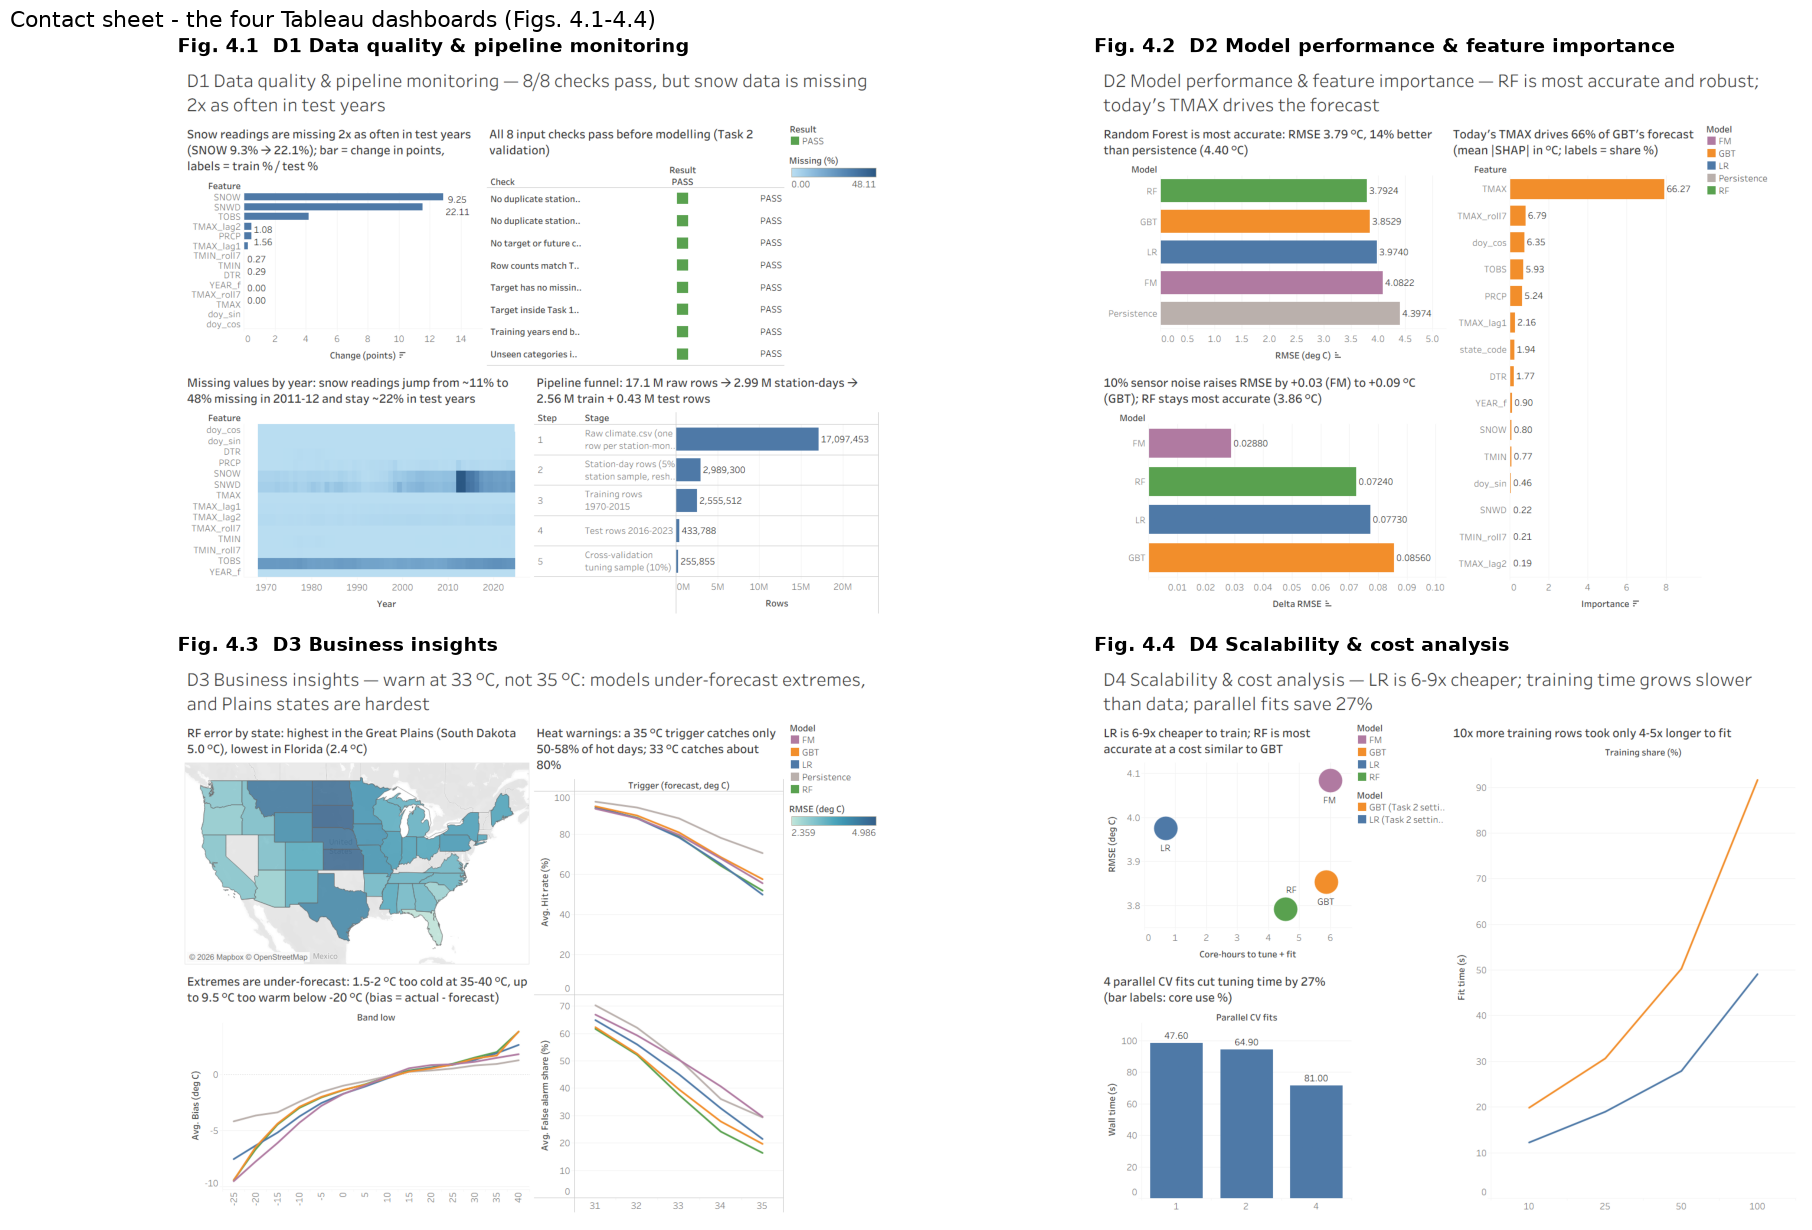

saved: task4/figures/task4_contact_sheet.png


In [11]:
# ==============================================================================
# 4.4  Contact sheet: the four dashboard images on one page (answer sheet 4.1)
## AI: image layout written with AI assistance
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
TITLES = {"D1": "Fig. 4.1  D1 Data quality & pipeline monitoring", "D2": "Fig. 4.2  D2 Model performance & feature importance",
          "D3": "Fig. 4.3  D3 Business insights", "D4": "Fig. 4.4  D4 Scalability & cost analysis"}
found = {k: next(iter(sorted(DASH_DIR.glob(f"{k}*.png")) + sorted(DASH_DIR.glob(f"{k}*.jpg"))), None) for k in TITLES}
if all(found.values()):
    fig, axes = plt.subplots(2, 2, figsize=(20, 12.5))
    for ax, (k, path) in zip(axes.ravel(), found.items()):
        ax.imshow(mpimg.imread(path)); ax.set_title(TITLES[k], fontsize=14, loc="left", fontweight="bold"); ax.axis("off")
    fig.suptitle("Contact sheet - the four Tableau dashboards (Figs. 4.1-4.4)", x=0.01, ha="left", fontsize=16)
    fig.tight_layout(); fig.savefig(FIG_DIR / "task4_contact_sheet.png", dpi=150, bbox_inches="tight"); plt.show()
    print("saved:", rel(FIG_DIR / "task4_contact_sheet.png"))
else:
    print("Dashboard images not found yet:", [k for k, v in found.items() if v is None])
    print(f"Export each dashboard from Tableau as an image into {rel(DASH_DIR)}/ as D1.png ... D4.png, then re-run this cell.")

In [10]:
# ==============================================================================
# 4.5  results/task4.json - the four dashboards, the exports, the Tableau Public link and the key numbers
## AI: JSON layout written with AI assistance
# ==============================================================================
DASHBOARDS = [
    {"id": "D1", "name": "Data quality & pipeline monitoring", "tables": [n for n, (d, _) in EXPORTS.items() if d == "D1"]},
    {"id": "D2", "name": "Model performance & feature importance", "tables": [n for n, (d, _) in EXPORTS.items() if d == "D2"]},
    {"id": "D3", "name": "Business insights", "tables": [n for n, (d, _) in EXPORTS.items() if d == "D3"]},
    {"id": "D4", "name": "Scalability & cost analysis", "tables": [n for n, (d, _) in EXPORTS.items() if d == "D4"]},
]
RESULTS = {
    "task": 4, "notebook": NOTEBOOK, "quick_test": QUICK_TEST, "student": task1.get("student"),
    "pool_reference": task1.get("pool_reference"), "problem_type": "regression", "target_col": TARGET,
    "input_contract": ["results/task1.json", "results/task2.json", "results/task3.json"],
    "tableau_public_url": TABLEAU_PUBLIC_URL or None, "dashboards": DASHBOARDS, "n_dashboards": len(DASHBOARDS),
    "exports": EXPORT_LIST.to_dict("records"), "excel_workbook": rel(XLSX) if XLSX else None,
    "contact_sheet": rel(FIG_DIR / "task4_contact_sheet.png") if (FIG_DIR / "task4_contact_sheet.png").exists() else None,
    "key_numbers": KEY_NUMBERS, "scaling": SCALING.to_dict("records"), "executor_config": EXECUTOR_CONFIG,
    "written_at": time.strftime("%Y-%m-%d %H:%M:%S"),
}
(RES_DIR / "task4_results.json").write_text(json.dumps(RESULTS, indent=2, default=str))
print("saved:", rel(RES_DIR / "task4_results.json"))
if not QUICK_TEST:
    brief_json = ROOT / "results" / "task4.json"
    if (not brief_json.exists()) or json.loads(brief_json.read_text()).get("notebook") == NOTEBOOK:
        brief_json.write_text(json.dumps(RESULTS, indent=2, default=str)); print("saved:", rel(brief_json))
if not TABLEAU_PUBLIC_URL:
    print("REMINDER: paste the Tableau Public link into TABLEAU_PUBLIC_URL (cell 0.1) and re-run 0.1 and 4.5 - "
          "the checklist reads it from results/task4.json")

saved: task4/results/task4_results.json
saved: results/task4.json
REMINDER: paste the Tableau Public link into TABLEAU_PUBLIC_URL (cell 0.1) and re-run 0.1 and 4.5 - the checklist reads it from results/task4.json
